# UMAP

UMAP (Uniform Manifold Approximation and Projection) is a popular dimensionality reduction technique used in machine learning to simplify complex data with hundreds or thousands of features down to 2D or 3D so humans can visualize and analyze it.

# For more information click the link below

https://docs.google.com/document/d/1pUAxE9_5Fna5cWLtuBZ1M0-6oMUb3dKTHMp1bQuw_NQ/edit?usp=sharing

# Notes and interview question and answer .


https://docs.google.com/document/d/1A55Q8Ww7YdNV6t-0igkN8er89NgGHmqLRu2DgzeIBW4/edit?usp=sharing

# Coding

# Import libraries 


In [12]:
! pip install umap-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 11.7 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.5/40.5 MB 7.0 MB/s  0:00:05m0:00:0100:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [umap-learn]5 [numba]te]

[notice] A new release of pip is available: 26.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [13]:
from sklearn.datasets import load_digits
import numpy as np                                      # Numerical calculations
import pandas as pd                                     # Data manipulation
import matplotlib.pyplot as plt                         # Visualization

from sklearn.datasets import load_digits                # Built-in handwritten digits dataset
from sklearn.preprocessing import StandardScaler        # Feature scaling

import umap                                              # UMAP dimensionality reduction

/Users/shyamalkar/Desktop/ML/mlvenv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# load the dataset 

In [14]:
digits = load_digits()                                  # Load the handwritten digits dataset

X = digits.data                                         # 64 pixel features
y = digits.target                                       # Digit labels from 0–9

print("X shape:", X.shape)                              # 1797 samples × 64 features
print("y shape:", y.shape)                              # 1797 labels

X shape: (1797, 64)
y shape: (1797,)


# Scale the features 

In [15]:
scaler = StandardScaler()                               # Creates the standardization object

X_scaled = scaler.fit_transform(
    X                                                     # Standardize all 64 pixel features
)

print("Scaled shape:", X_scaled.shape)                  # Scaling doesn't change dimensions

Scaled shape: (1797, 64)


# Create the UMAP model 

In [16]:
reducer = umap.UMAP(
    n_components=2,                                     # Reduce 64 dimensions to 2
    n_neighbors=15,                                     # Number of neighboring points used to construct local structure
    min_dist=0.1,                                       # Controls how tightly points can be packed together
    metric="euclidean",                                 # Distance measure used between observations
    random_state=42                                     # Makes the result reproducible
)

# Apply UMAP

In [18]:
X_umap = reducer.fit_transform(
    X_scaled                                            # Learn the low-dimensional representation
)

print("Original shape:", X.shape)                       # 1797 × 64
print("UMAP shape:", X_umap.shape)                     # 1797 × 2

/Users/shyamalkar/Desktop/ML/mlvenv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Original shape: (1797, 64)
UMAP shape: (1797, 2)


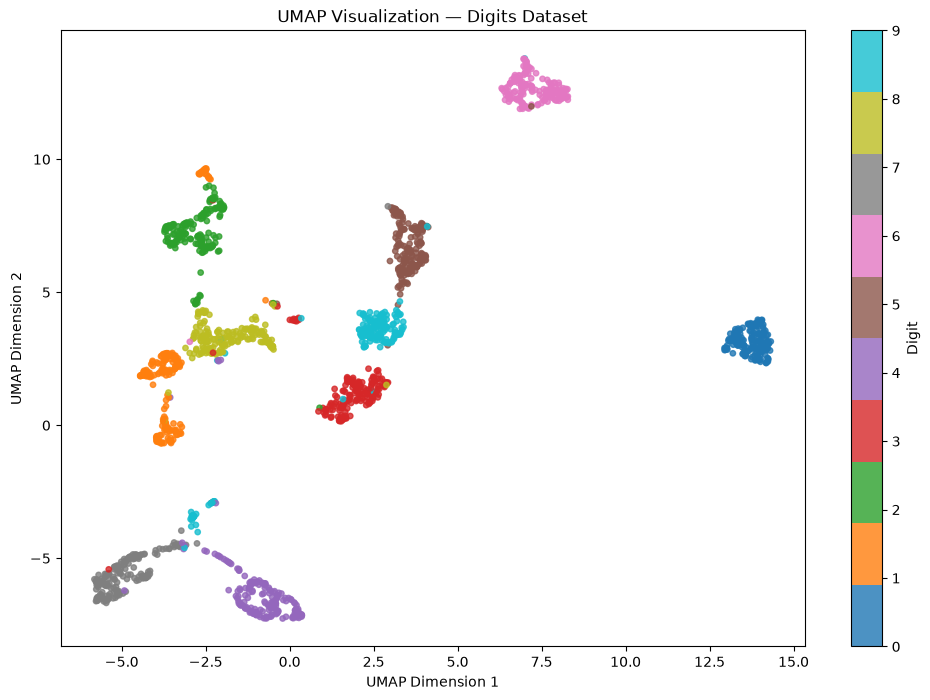

In [19]:
plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    X_umap[:, 0],                                      # First UMAP dimension
    X_umap[:, 1],                                      # Second UMAP dimension
    c=y,                                                # Labels used only for visualization
    cmap="tab10",                                       # Different color for each digit
    s=15,                                               # Point size
    alpha=0.8                                           # Point transparency
)

plt.xlabel("UMAP Dimension 1")
plt.ylabel("UMAP Dimension 2")
plt.title("UMAP Visualization — Digits Dataset")

plt.colorbar(
    scatter,
    label="Digit"
)

plt.show()

# Experiment with n_neighbors 

/Users/shyamalkar/Desktop/ML/mlvenv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/shyamalkar/Desktop/ML/mlvenv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/shyamalkar/Desktop/ML/mlvenv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/shyamalkar/Desktop/ML/mlvenv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


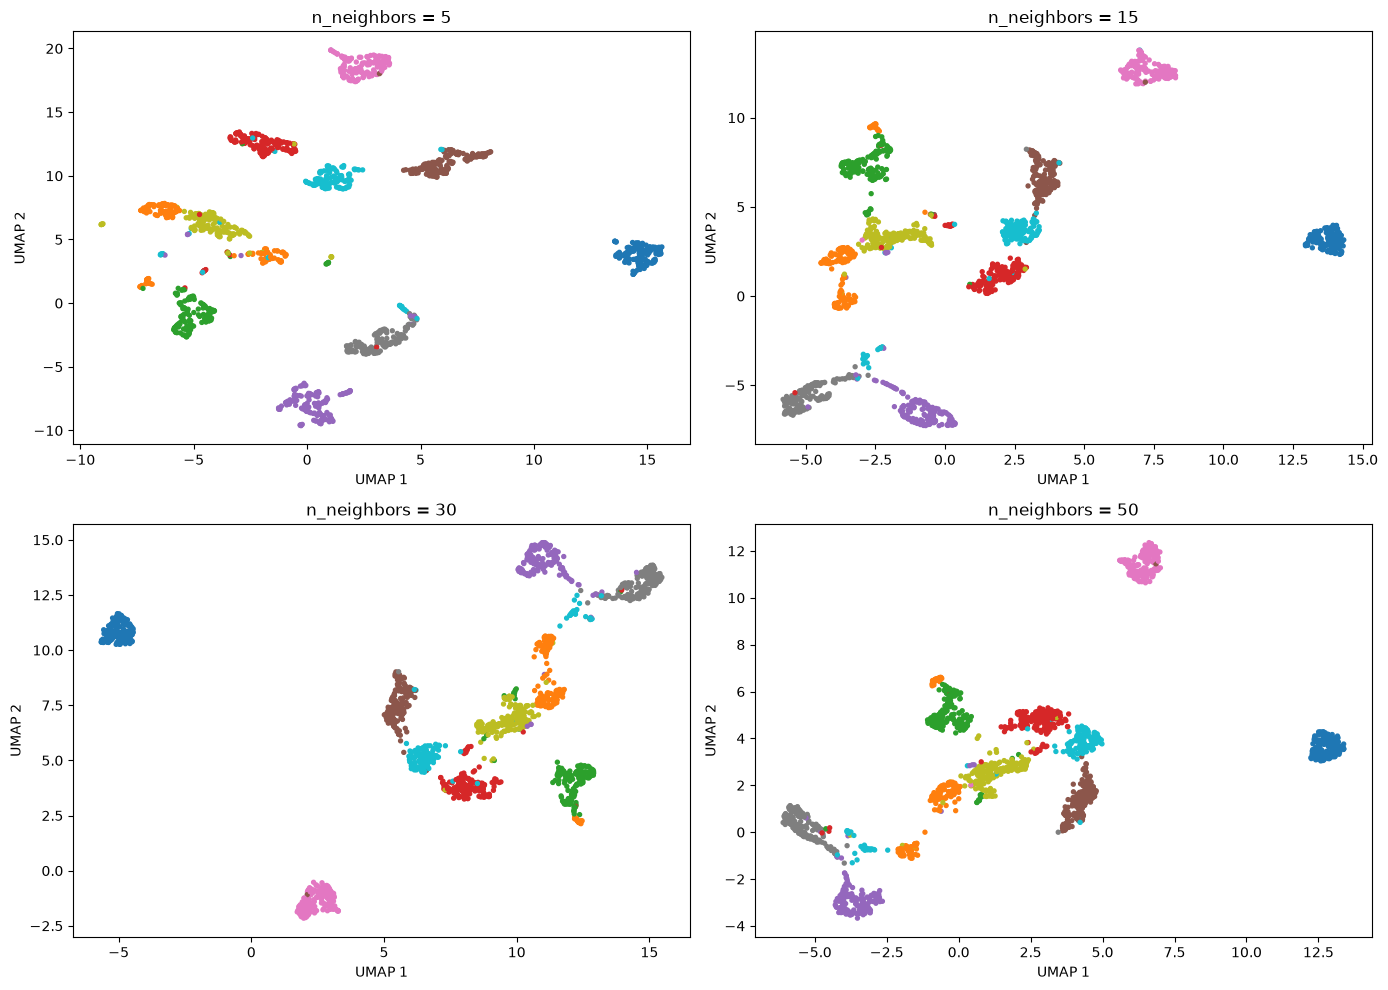

In [20]:
neighbors = [5, 15, 30, 50]                           # Different neighborhood sizes

fig, axes = plt.subplots(
    2, 2,                                                # Create four plots
    figsize=(14, 10)
)

for ax, n in zip(axes.ravel(), neighbors):

    reducer = umap.UMAP(
        n_components=2,                                  # Reduce to 2 dimensions
        n_neighbors=n,                                   # Change neighborhood size
        min_dist=0.1,                                    # Keep minimum distance fixed
        metric="euclidean",                              # Use Euclidean distance
        random_state=42                                  # Reproducible result
    )

    X_umap_temp = reducer.fit_transform(
        X_scaled                                         # Generate UMAP embedding
    )

    scatter = ax.scatter(
        X_umap_temp[:, 0],                               # UMAP dimension 1
        X_umap_temp[:, 1],                               # UMAP dimension 2
        c=y,                                             # Color according to digit
        cmap="tab10",
        s=8
    )

    ax.set_title(f"n_neighbors = {n}")
    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")

plt.tight_layout()
plt.show()

/Users/shyamalkar/Desktop/ML/mlvenv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/shyamalkar/Desktop/ML/mlvenv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/shyamalkar/Desktop/ML/mlvenv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/shyamalkar/Desktop/ML/mlvenv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


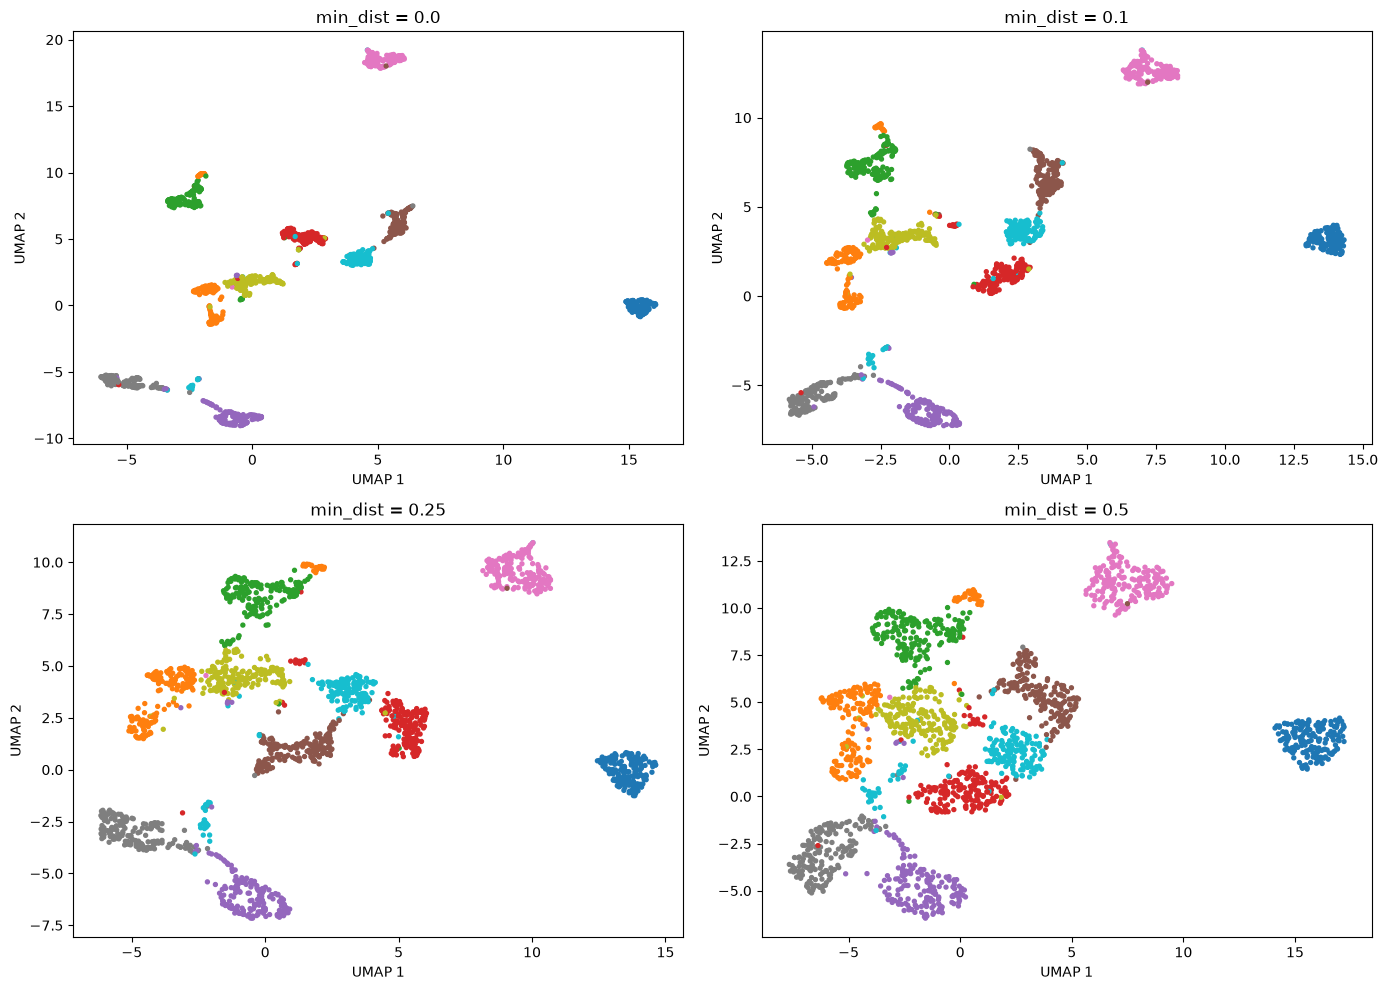

In [21]:
# Experiment with min_dist 

distances = [0.0, 0.1, 0.25, 0.5]                    # Different minimum-distance values

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10)
)

for ax, distance in zip(axes.ravel(), distances):

    reducer = umap.UMAP(
        n_components=2,                                # Reduce to 2 dimensions
        n_neighbors=15,                                # Keep neighborhood size fixed
        min_dist=distance,                              # Change how tightly points can cluster
        metric="euclidean",                             # Use Euclidean distance
        random_state=42                                 # Reproducible result
    )

    X_umap_temp = reducer.fit_transform(
        X_scaled                                        # Generate UMAP embedding
    )

    scatter = ax.scatter(
        X_umap_temp[:, 0],                              # UMAP dimension 1
        X_umap_temp[:, 1],                              # UMAP dimension 2
        c=y,                                            # Color according to digit
        cmap="tab10",
        s=8
    )

    ax.set_title(f"min_dist = {distance}")
    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")

plt.tight_layout()
plt.show()